In [74]:
%run 00_utils.ipynb

%load_ext autoreload
%autoreload 2

Root-Verzeichnis: /home/jessh/Study/Bachelor-Thesis
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [75]:
from pathlib import Path
import cv2, os
import numpy as np
from data_handler.dataset import AntiUAVDataset
import albumentations as A

In [76]:
train_data = AntiUAVDataset(TRAINING_DIR)

ORG:    /home/jessh/Study/Bachelor-Thesis/data/Anti-UAV410/train/20190926_143632_1_7/000633.jpg


/tmp/ipykernel_29742/3748119068.py:15: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(1.0, 5.0), p=PROB),
/tmp/ipykernel_29742/3748119068.py:27: UserWarning: Argument(s) 'shift_limit' are not valid for transform OpticalDistortion
  [A.OpticalDistortion(distort_limit=0.05, shift_limit=0.05, p=PROB),
/tmp/ipykernel_29742/3748119068.py:28: UserWarning: Argument(s) 'distort_range' are not valid for transform GridDistortion
  A.GridDistortion(num_steps=5, distort_range=(-0.1, 0.1), p=PROB)],


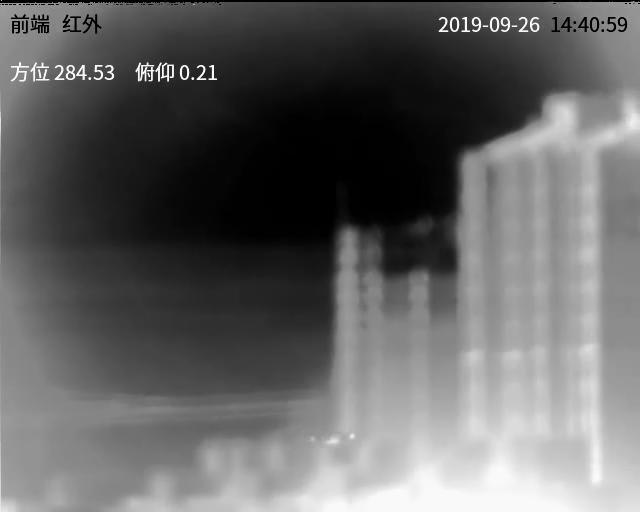



GaussNoise


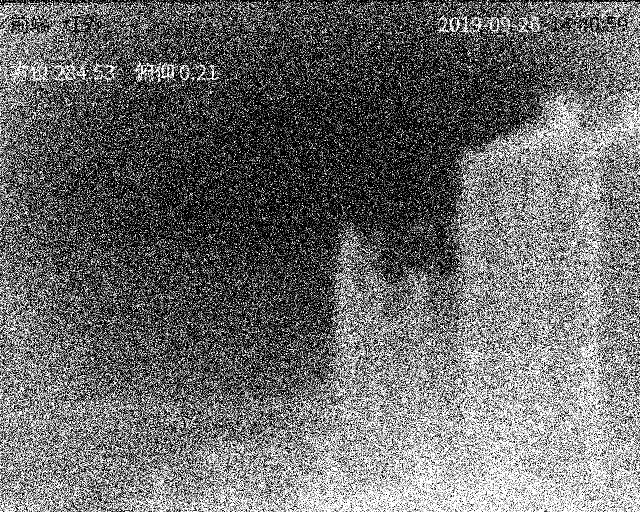

GaussianBlur


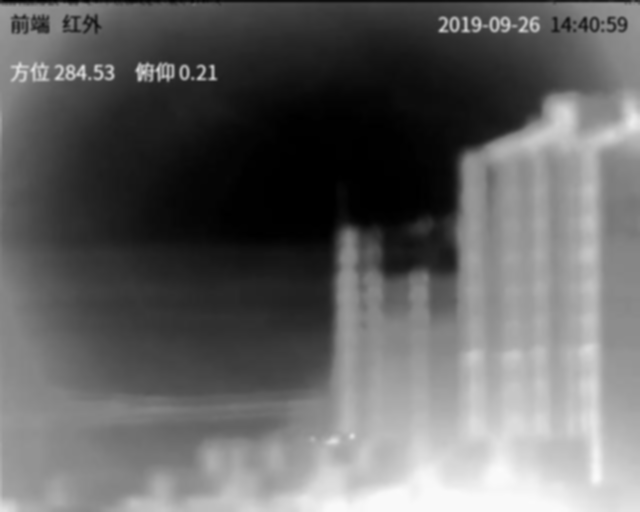

RandomBrightnessContrast


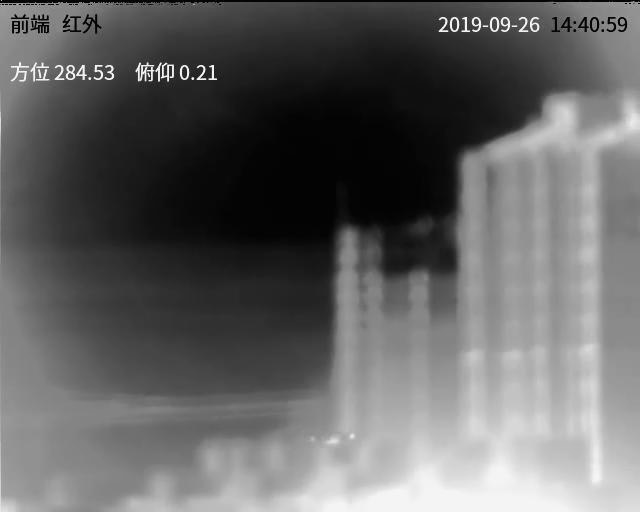

CLAHE


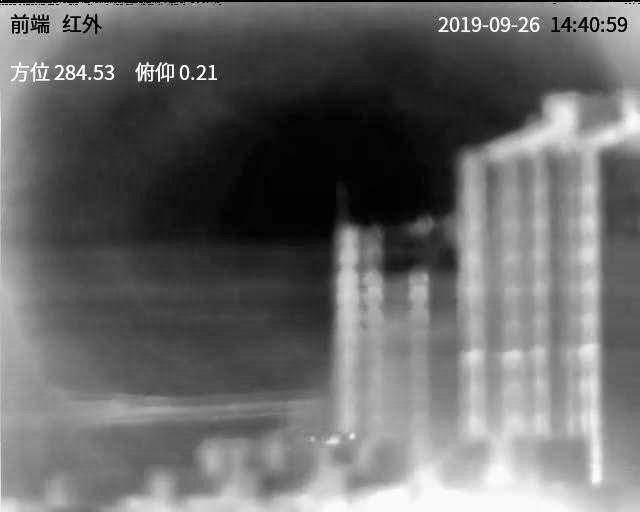

OpticalDistortion GridDistortion


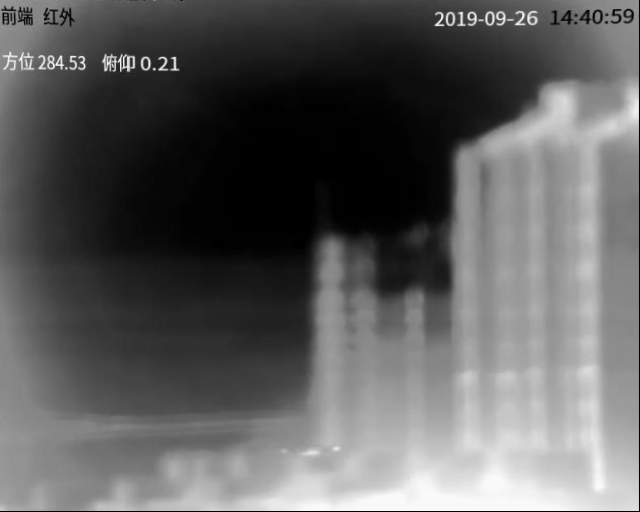

In [77]:
def wrap(transform):
    # Falls nur ein einzelner Transform übergeben wurde, in eine Liste packen
    if not isinstance(transform, (list, tuple)):
        transform = [transform]
        
    return A.Compose(
        transform, 
        bbox_params=A.BboxParams(format='coco', label_fields=['class_labels']),
        save_applied_params=True
    )

PROB = 1.0
transforms = [
    # 1. Simuliert thermisches Rauschen des Sensors
    A.GaussNoise(var_limit=(1.0, 5.0), p=PROB),
    
    # 2. Simuliert Thermal Blooming (leichtes Verschwimmen der Hitze)
    A.GaussianBlur(blur_limit=(3, 5), p=PROB),
    
    # 3. Simuliert Thermal Crossover / wechselnde Temperaturkontraste
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.2, p=PROB),
    
    # 4. Verbessert/verschlechtert lokale Kontraste (wie echte Wärmebilder)
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=PROB),
    
    # 5. Simuliert Hitzeflimmern in Bodennähe
    [A.OpticalDistortion(distort_limit=0.05, shift_limit=0.05, p=PROB),
     A.GridDistortion(num_steps=5, distort_range=(-0.1, 0.1), p=PROB)],
]

b_show_org= True
for transform in transforms:

    train_data.transform = wrap(transform)
    img, target, img_org = train_data[100000]

    if b_show_org:
        print(f"ORG:    {target['img_path']}")
        show_img(img_org)
        print("\n")
        b_show_org = not b_show_org
        
    
    print(" ".join([k[0] for k in target["applied_transforms"]]))
    show_img(img)